# 03 · Baseline y SARIMA (tarea A6)

**Fase CRISP-DM:** modelado. SARIMA sobre `log1p(y)`, sin variables exógenas. Los órdenes se eligieron
con `python -m src.models.arima select`, que solo ve datos hasta el fin de validación, y quedaron
congelados antes de generar la prueba. Este notebook **lee** esos resultados; la lógica está en
`src/models/arima.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import *
from src.features.exog import load_history

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.float_format", "{:,.3f}".format, "display.width", 160)
history = load_history()
LEVELS = ["total", *LEVELS_TYPES]

import json
from statsmodels.stats.diagnostic import acorr_ljungbox
from src.models.arima import SELECTION_FILE, GRID_FILE, ROLLING_FILE, Spec, USES_EXOG, fit_model, level_data, training_target
warnings.filterwarnings("ignore")
ALL_LEVELS = ["total", *LEVELS_TYPES, *[f"store_{n}" for n in SELECTED_STORES]]
sel = json.loads(SELECTION_FILE.read_text("utf-8"))["levels"]
grid = pd.read_csv(GRID_FILE)
def metricas(modelo):
    return json.loads((ARTIFACTS / "metrics" / f"{modelo}.json").read_text("utf-8"))["levels"]
def spec(uid, modelo):
    c = sel[uid][modelo]; return Spec(tuple(c["order"]), tuple(c["seasonal_order"]))
def ajustar(uid, modelo, corte):
    y, x = level_data(history, uid); y = y.loc[:corte]
    return fit_model(training_target(y, x), x.loc[:corte] if USES_EXOG[modelo] else None, spec(uid, modelo))
def ljung(res, lags=(7, 14, 28)):
    r = pd.Series(res.resid).iloc[max(res.loglikelihood_burn, 14):].dropna()
    t = acorr_ljungbox(r, lags=list(lags)); return t["lb_pvalue"].to_dict()
def comparar(split):
    n, a, b = metricas("naive"), metricas("sarima"), metricas("sarimax")
    return pd.DataFrame([{"nivel": u, **{f"{m} {k}": d[u][split][k] for m, d in [("naive", n), ("sarima", a), ("sarimax", b)] for k in ("rmse", "mape")}} for u in ALL_LEVELS]).set_index("nivel")

## 1. Búsqueda de órdenes

Rejilla p, q ∈ {0, 1, 2} y P, Q ∈ {0, 1}, con d según `choose_d`, D = 1 y s = 7. Pasan a la final los 5 mejores por AIC más el modelo de AutoARIMA, y gana el menor **RMSE de validación**.

In [2]:
g = grid[grid["model"] == "sarima"]
print("Candidatos:", len(g), "| válidos:", int(g["valid"].sum()))
filas = []
for u in ALL_LEVELS:
    v = g[(g["unique_id"] == u) & g["valid"]]; r = v[v["source"] == "grid"]; a = v[v["source"] == "auto_arima"].iloc[0]
    mejor_aic = r.sort_values("aic").iloc[0]; c = sel[u]["sarima"]
    filas.append({"nivel": u, "elegido": f"{tuple(c['order'])}{tuple(c['seasonal_order'][:3])}", "origen": c["source"], "RMSE elegido": c["rmse"],
                  "RMSE mejor AIC": mejor_aic["rmse"], "RMSE AutoARIMA": a["rmse"], "AutoARIMA": f"{a['order']}{a['seasonal_order']}"})
display(pd.DataFrame(filas).set_index("nivel"))

Candidatos: 370 | válidos: 367


,elegido,origen,RMSE elegido,RMSE mejor AIC,RMSE AutoARIMA,AutoARIMA
nivel,,,,,,
total,"(2, 0, 2)(0, 1, 1)",grid,"2,192,460.585","2,195,575.190","2,200,332.380","[0, 0, 1][0, 1, 1, 7]"
type_a,"(0, 0, 2)(0, 1, 1)",grid,"1,262,880.242","1,263,361.688","1,263,598.019","[1, 0, 2][1, 1, 1, 7]"
type_b,"(0, 1, 1)(1, 1, 1)",grid,"20,776.078","21,207.662","24,218.596","[1, 0, 5][1, 1, 2, 7]"
type_c,"(1, 0, 2)(0, 1, 1)",grid,"394,801.653","397,126.768","396,248.132","[0, 0, 1][0, 1, 1, 7]"
type_d,"(0, 0, 2)(0, 1, 1)",grid,"771,205.839","816,838.277","822,031.217","[0, 0, 1][1, 1, 1, 7]"
store_9,"(2, 0, 2)(1, 1, 1)",grid,"3,257.116","3,257.137","3,279.260","[0, 0, 0][0, 1, 1, 7]"
store_769,"(2, 1, 2)(1, 1, 1)",grid,"1,325.567","1,328.227","1,417.479","[0, 1, 5][0, 0, 2, 7]"
store_504,"(2, 0, 2)(0, 1, 1)",grid,"2,281.422","2,281.422","2,295.302","[0, 0, 0][0, 1, 1, 7]"
store_960,"(2, 0, 2)(0, 1, 1)",grid,"2,737.918","2,914.472","2,743.703","[0, 0, 1][0, 1, 1, 7]"


> **Conclusión:** se evaluaron 370 candidatos y 367 ajustaron de forma válida. En los 10 niveles ganó un modelo de la rejilla; AutoARIMA nunca quedó primero. Elegir por RMSE de validación entre los finalistas por AIC cambia poco en la mayoría de los niveles (0,1 % en el total), pero mejora cerca de un 6 % en `type_d` y `store_960`.

## 2. Diagnóstico de residuos (total, ajustado con entrenamiento)

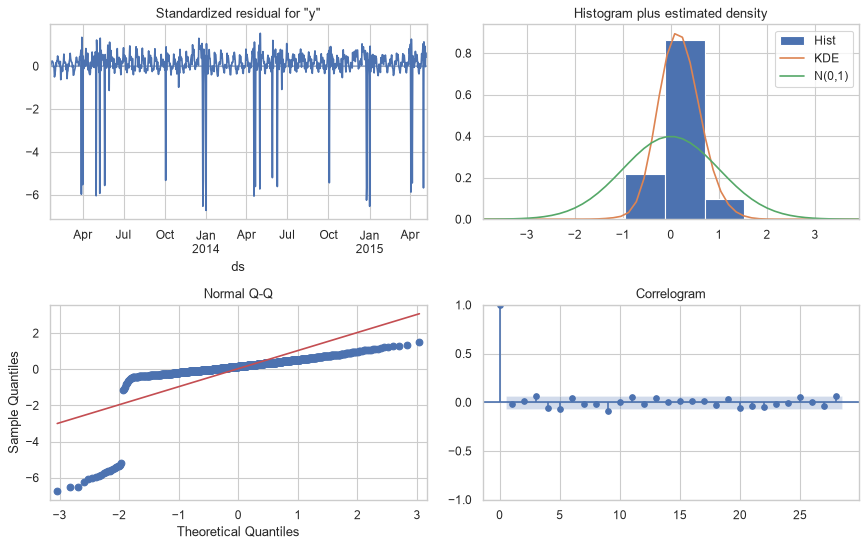

,p Ljung-Box lag 7,p Ljung-Box lag 14,p Ljung-Box lag 28
total,0.093,0.050,0.094
type_a,0.160,0.319,0.481
type_b,0.000,0.000,0.000
type_c,0.044,0.031,0.099
type_d,0.067,0.002,0.008


In [3]:
res = ajustar("total", "sarima", TRAIN_END)
fig = res.plot_diagnostics(figsize=(11, 7), lags=28); plt.tight_layout(); plt.show()
display(pd.DataFrame({u: ljung(ajustar(u, "sarima", TRAIN_END)) for u in ["total", *LEVELS_TYPES]}).T.rename(columns=lambda k: f"p Ljung-Box lag {k}"))

> **Conclusión:** con un nivel del 5 %, Ljung-Box no rechaza residuos sin autocorrelación en `type_a`, y en el total queda en el límite (p = 0,09; 0,05; 0,09). Sí rechaza en todos los lags de `type_b`, en los lags 7 y 14 de `type_c` y en los lags 14 y 28 de `type_d`. SARIMA no recibe la promoción, que alterna cada dos semanas, así que un resto de estructura en el lag 14 es coherente con esa omisión.

## 3. Resultados frente al baseline

Validación


,naive rmse,sarima rmse,naive mape,sarima mape,SARIMA gana en RMSE
nivel,,,,,
total,"2,655,513.310","2,192,460.585",171.152,120.417,True
type_a,"1,458,823.445","1,262,880.242",677.151,462.224,True
type_b,"22,815.634","20,776.078",9.620,8.181,True
type_c,"342,792.543","394,801.653",19.858,31.219,False
type_d,"863,068.704","771,205.839","1,396.544",987.791,True
store_9,"2,860.986","3,257.116",17.380,36.737,False
store_769,"1,480.514","1,325.567",9.353,7.733,True
store_504,"2,343.425","2,281.422",19.771,25.084,True
store_960,"2,886.540","2,737.918",24.200,28.319,True


Prueba (usada una sola vez)


,naive rmse,sarima rmse,naive mape,sarima mape,SARIMA gana en RMSE
nivel,,,,,
total,"1,775,080.153","1,734,123.029",17.413,17.075,True
type_a,"931,087.763","992,364.947",18.721,22.292,False
type_b,"22,299.084","18,846.196",9.792,8.508,True
type_c,"227,874.604","409,073.947",19.564,33.425,False
type_d,"601,578.302","600,180.556",20.739,19.874,True
store_9,"1,799.714","3,120.418",22.170,36.115,False
store_769,"1,567.571","1,621.133",10.086,11.124,False
store_504,"1,357.934","2,305.705",15.681,25.277,False
store_960,"2,110.659","2,686.905",28.756,29.795,False


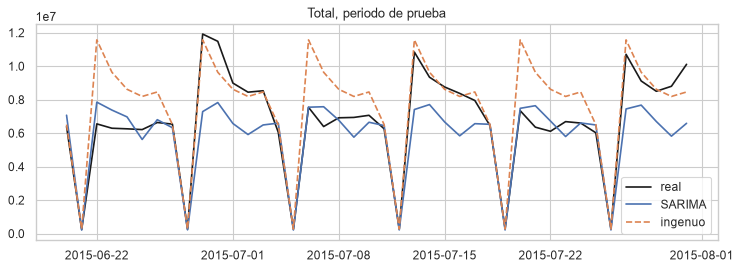

In [4]:
for split, nombre in [("val", "Validación"), ("test", "Prueba (usada una sola vez)")]:
    t = comparar(split)[["naive rmse", "sarima rmse", "naive mape", "sarima mape"]]
    t["SARIMA gana en RMSE"] = t["sarima rmse"] < t["naive rmse"]; print(nombre); display(t)
fc = pd.read_parquet(ARTIFACTS / "forecasts" / "sarima.parquet"); nv = pd.read_parquet(ARTIFACTS / "forecasts" / "naive.parquet")
fig, ax = plt.subplots(figsize=(11, 3.5)); f = fc[(fc.unique_id == "total") & (fc.split == "test")]; n = nv[(nv.unique_id == "total") & (nv.split == "test")]
ax.plot(f.ds, f.y, "k", label="real"); ax.plot(f.ds, f.y_hat, label="SARIMA"); ax.plot(n.ds, n.y_hat, ls="--", label="ingenuo"); ax.legend(); ax.set_title("Total, periodo de prueba"); plt.show()

> **Conclusión:** SARIMA gana al ingenuo en RMSE en 8 de 10 niveles en validación, pero solo en 4 de 10 en prueba (total, `type_b`, `type_d` y `store_693`). En el total la mejora en prueba es de apenas 2,3 % y el MAPE es 17,1 %. Solo `type_b` y `store_769` quedan bajo el 15 %. El MAPE de validación del total es muy alto porque hay festivos con venta mínima que ni SARIMA ni el ingenuo conocen. Conclusión: la estructura temporal sola no basta; hacen falta promoción y calendario.